# CS 215 – Team 51: Vulture decline and human deaths
## Harsh & Vishal's part: cleaning, summary statistics, and the Q1 / Q7 / Q8 regressions

We start from Kartik's merged file `district_analysis_panel.csv` (district × year, 1988–1995) and use the data as it is given.
Population (from the 1992 mortality file) and the state-level panel (`state_mortality_panel.dta`) are the only extra pieces we pull in.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

pd.set_option("display.width", 180)
pd.set_option("display.max_columns", 30)

# folders: same layout as Kartik's notebook, with a fallback for a flat folder
def find(name):
    for folder in ["../data/clean", "../data/raw", "/mnt/user-data/uploads", "."]:
        for n in (name, name.replace("_", " ")):
            path = os.path.join(folder, n)
            if os.path.exists(path):
                return path
    raise FileNotFoundError(name)

panel = pd.read_csv(find("district_analysis_panel.csv"))
print(panel.shape)
panel.head()

(1400, 9)
            state       district  year  drural  durban  total_deaths  vulture_habitat  cattle  dog_govt
0  andhra pradesh       chittoor  1988  7481.0  3074.0       10555.0                1  829.72    36.702
1  andhra pradesh       chittoor  1989  7279.0  3143.0       10422.0                1  829.72    36.702
2  andhra pradesh  east godavari  1988  5009.0  5935.0       10944.0                1  371.76    32.110
3  andhra pradesh  east godavari  1989  3782.0  6103.0        9885.0                1  371.76    32.110
4  andhra pradesh         guntur  1988  9068.0  6322.0       15390.0                1  265.10    10.393


## 1. Cleaning

In [2]:
# --- basic checks on Kartik's panel ---
print("duplicate district-years:", panel.duplicated(["state", "district", "year"]).sum())
print("districts:", panel.groupby(["state", "district"]).ngroups, "| states:", panel.state.nunique(), "| years:", panel.year.min(), "-", panel.year.max())
print()
print("missing values per column:")
print(panel.isna().sum())

# total_deaths was built with fillna(0), so missing deaths turned into zeros / partial sums
missing_any = panel.drural.isna() | panel.durban.isna()
print()
print("rows with rural or urban deaths missing:", missing_any.sum())
print("   of which total_deaths shows 0:", (missing_any & (panel.total_deaths == 0)).sum())
print("rows with a zero death count in rural or urban:", ((panel.drural == 0) | (panel.durban == 0)).sum())

duplicate district-years: 0
districts: 181 | states: 15 | years: 1988 - 1995

missing values per column:
state                0
district             0
year                 0
drural              74
durban              74
total_deaths         0
vulture_habitat      0
cattle              77
dog_govt           863
dtype: int64

rows with rural or urban deaths missing: 88
   of which total_deaths shows 0: 60
rows with a zero death count in rural or urban: 10


In [3]:
df = panel.copy()

# 1) missing deaths stay missing; a count of exactly 0 for a whole district-year is a reporting gap, not a real zero
df.loc[df.drural <= 0, "drural"] = np.nan
df.loc[df.durban <= 0, "durban"] = np.nan
df["total_deaths"] = df["drural"] + df["durban"]          # NaN unless both are known

# 2) dog_govt is mostly missing (61%) -> not usable as a control, drop it
df = df.drop(columns="dog_govt")

# 3) population: Kartik's file has no denominator, and big districts simply have more deaths.
#    The 1992 mortality file holds the 1991 census population, so we merge it on state + district.
pop = pd.read_csv(find("Mortality_districts_1992.csv"))
pop = pop.loc[pop.year == 1991, ["state", "district", "poprural", "popurban"]]
for c in ["poprural", "popurban"]:
    pop[c] = pd.to_numeric(pop[c], errors="coerce")        # '.' placeholders in the raw file become NaN
df = df.merge(pop, on=["state", "district"], how="left")
print("rows with population:", df.poprural.notna().mean().round(3))

# 4) death rates per 1000 people (1991 population used as the fixed denominator) and logs
df["rural_rate"] = df.drural / df.poprural * 1000
df["total_rate"] = df.total_deaths / (df.poprural + df.popurban) * 1000
df["ln_rural_rate"] = np.log(df.rural_rate)
df["ln_total_rate"] = np.log(df.total_rate)
df["ln_drural"] = np.log(df.drural)

# 5) cattle: standardise across districts so that the vulture coefficient means "at average cattle"
districts = df.drop_duplicates(["state", "district"]).dropna(subset=["cattle"])
df["cattle_z"] = (df.cattle - districts.cattle.mean()) / districts.cattle.std()
df["vulture"] = df.vulture_habitat
df["vulture_x_cattle"] = df.vulture * df.cattle_z
df["t"] = df.year - 1988
df["district_id"] = df.state + " | " + df.district

# analysis sample: needs a rural death rate and cattle
data = df.dropna(subset=["ln_rural_rate", "cattle_z"]).copy()
print("analysis sample:", data.shape[0], "district-years,", data.district_id.nunique(), "districts")

rows with population: 0.994
analysis sample: 1239 district-years, 164 districts


## 2. Summary statistics

In [4]:
cols = ["drural", "durban", "total_deaths", "rural_rate", "total_rate", "cattle"]
summary = data[cols].describe().T
summary["skew"] = data[cols].skew()
summary.round(2)

               count     mean      std     min      25%      50%       75%       max  skew
drural        1239.0  6229.82  6127.06    4.00  2646.00  4730.00   8146.50  76586.00  4.32
durban        1217.0  2927.63  3292.36   87.00   897.00  1765.00   3843.00  27175.00  3.05
total_deaths  1217.0  9217.61  7681.49  322.00  4179.00  7241.00  11629.00  80104.00  2.82
rural_rate    1239.0     3.86     2.64    0.00     1.78     3.39      5.52     19.64  1.22
total_rate    1217.0     4.21     2.40    0.10     2.26     3.95      5.90     17.54  0.81
cattle        1239.0   556.58   308.01   21.35   305.37   522.78    720.64   2096.78  1.37


In [5]:
# districts with and without vulture habitat
dd = data.drop_duplicates("district_id")
print("districts with vulture habitat:", int((dd.vulture == 1).sum()), "| without:", int((dd.vulture == 0).sum()))
print()
print(data.groupby("vulture")[["rural_rate", "total_rate", "cattle"]].mean().round(2))
print()
print("mean rural deaths per 1000, by year:")
print(data.groupby(["year", "vulture"]).rural_rate.mean().unstack().round(2))
print()
print(data.groupby("state").agg(districts=("district_id", "nunique"), vulture_share=("vulture", "mean"),
                                cattle=("cattle", "mean"), rural_rate=("rural_rate", "mean")).round(2))

districts with vulture habitat: 149 | without: 15

         rural_rate  total_rate  cattle
vulture                                
0              3.83        4.37  519.35
1              3.86        4.20  559.89

mean rural deaths per 1000, by year:
vulture     0     1
year               
1988     3.88  3.24
1989     3.72  3.63
1990     4.01  3.63
1991     3.96  3.83
1992     3.86  4.02
1993     3.53  4.06
1994     3.62  4.09
1995     4.06  4.20

                  districts  vulture_share   cattle  rural_rate
state                                                          
andhra pradesh            7           1.00   476.16        2.06
assam                     2           0.00   906.07        1.17
gujarat                   8           1.00   321.90        4.42
haryana                   2           1.00   237.29        6.24
himachal pradesh          3           0.00   255.35        2.81
karnataka                12           1.00   625.76        4.83
kerala                    3           

## 3. Q1 – Interaction effect: vulture habitat × cattle

Idea from the proposal: deaths should rise only where vultures lived **and** cattle were many.
Outcome = log of rural deaths per 1000 people. `vulture` = 1 if the district is Gyps indicus habitat, `cattle_z` = standardised cattle count.
Small helper for OLS with standard errors clustered by district (it gives the same numbers as `statsmodels` OLS with `cov_type="cluster"`).

In [6]:
def ols(d, y, xcols, fixed=(), cluster="district_id"):
    # OLS with dummy-variable fixed effects and cluster-robust standard errors
    d = d.dropna(subset=[y] + list(xcols))
    X = pd.concat([d[list(xcols)].astype(float), pd.Series(1.0, index=d.index, name="const")] +
                  [pd.get_dummies(d[f].astype(str), prefix=f, drop_first=True).astype(float) for f in fixed], axis=1)
    A, yy = X.values, d[y].values
    n, k = A.shape
    bread = np.linalg.pinv(A.T @ A)
    beta = bread @ A.T @ yy
    resid = yy - A @ beta
    g = pd.factorize(d[cluster])[0]
    G = g.max() + 1
    meat = sum(np.outer(A[g == i].T @ resid[g == i], A[g == i].T @ resid[g == i]) for i in range(G))
    cov = bread @ meat @ bread * G / (G - 1) * (n - 1) / (n - k)
    se = np.sqrt(np.diag(cov))
    out = pd.DataFrame({"coef": beta, "se": se, "t": beta / se,
                        "p": 2 * stats.t.sf(np.abs(beta / se), df=G - 1)}, index=X.columns).loc[list(xcols)]
    out.attrs["n"] = n
    out.attrs["clusters"] = G
    return out

def report(res, title):
    print(title, f"(N = {res.attrs['n']}, clusters = {res.attrs['clusters']})")
    print(res.round(3).to_string())
    print()

In [7]:
x = ["vulture", "cattle_z", "vulture_x_cattle"]

m1 = ols(data, "ln_rural_rate", x, fixed=["year"])
report(m1, "Model 1: ln rural death rate ~ vulture + cattle + vulture x cattle + year effects")

m2 = ols(data, "ln_rural_rate", x, fixed=["year", "state"])
report(m2, "Model 2: same, plus state effects (compares districts inside the same state)")

# Model 3: look at change over time inside each district (district effects remove everything that stays fixed)
for c in ["vulture", "cattle_z", "vulture_x_cattle"]:
    data[c + "_t"] = data[c] * data["t"]
m3 = ols(data, "ln_rural_rate", ["t", "vulture_t", "cattle_z_t", "vulture_x_cattle_t"], fixed=["district_id"])
report(m3, "Model 3: district effects, interactions with a time trend (vulture_x_cattle_t = extra yearly growth where vultures meet many cattle)")

Model 1: ln rural death rate ~ vulture + cattle + vulture x cattle + year effects (N = 1239, clusters = 164)
                   coef     se      t      p
vulture           0.097  0.212  0.457  0.648
cattle_z         -0.457  0.197 -2.313  0.022
vulture_x_cattle  0.636  0.207  3.070  0.003

Model 2: same, plus state effects (compares districts inside the same state) (N = 1239, clusters = 164)
                   coef     se      t      p
vulture           0.107  0.133  0.808  0.420
cattle_z         -0.176  0.094 -1.879  0.062
vulture_x_cattle  0.289  0.091  3.156  0.002

Model 3: district effects, interactions with a time trend (vulture_x_cattle_t = extra yearly growth where vultures meet many cattle) (N = 1239, clusters = 164)
                     coef     se      t      p
t                  -0.024  0.029 -0.823  0.412
vulture_t           0.043  0.031  1.408  0.161
cattle_z_t         -0.034  0.023 -1.467  0.144
vulture_x_cattle_t  0.002  0.026  0.083  0.934



                          early   late  change  districts
group                                                    
no vulture + high cattle  0.397  0.069  -0.328          7
no vulture + low cattle   1.656  1.521  -0.135          8
vulture + high cattle     1.234  1.274   0.040         61
vulture + low cattle      0.820  1.011   0.191         88


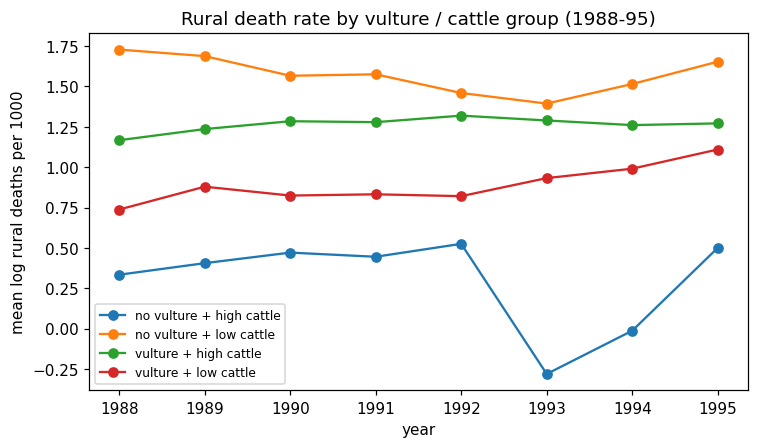

In [8]:
# Same question without regression: change in the rural death rate, early (1988-90) vs late (1993-95)
data["group"] = np.where(data.vulture == 1, "vulture", "no vulture") + np.where(data.cattle_z > 0, " + high cattle", " + low cattle")
early = data[data.year <= 1990].groupby("group").ln_rural_rate.mean()
late = data[data.year >= 1993].groupby("group").ln_rural_rate.mean()
change = pd.DataFrame({"early": early, "late": late, "change": late - early, "districts": data.groupby("group").district_id.nunique()})
print(change.round(3))

fig, ax = plt.subplots(figsize=(7, 4.2))
for g, d in data.groupby("group"):
    ax.plot(d.groupby("year").ln_rural_rate.mean(), marker="o", label=g)
ax.set_xlabel("year"); ax.set_ylabel("mean log rural deaths per 1000")
ax.set_title("Rural death rate by vulture / cattle group (1988-95)")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

In [9]:
# How solid is the Model 1 result? Re-run it leaving out one state at a time.
rows = []
for s in sorted(data.state.unique()):
    res = ols(data[data.state != s], "ln_rural_rate", x, fixed=["year"])
    rows.append({"state left out": s, "share of its districts with vultures": data[data.state == s].vulture.mean(),
                 "vulture x cattle": res.loc["vulture_x_cattle", "coef"], "p-value": res.loc["vulture_x_cattle", "p"]})
print(pd.DataFrame(rows).round(3).to_string(index=False))
print()
print("districts without vulture habitat by state:")
print(dd[dd.vulture == 0].groupby("state").size())

  state left out  share of its districts with vultures  vulture x cattle  p-value
  andhra pradesh                                 1.000             0.622    0.003
           assam                                 0.000             0.622    0.005
         gujarat                                 1.000             0.664    0.002
         haryana                                 1.000             0.651    0.002
himachal pradesh                                 0.000             0.730    0.001
       karnataka                                 1.000             0.629    0.003
          kerala                                 1.000             0.644    0.002
  madhya pradesh                                 1.000             0.651    0.002
     maharashtra                                 1.000             0.627    0.003
          orissa                                 1.000             0.642    0.004
          punjab                                 0.286             0.342    0.111
       rajasthan

In [10]:
# The district data stop in 1995, when the vulture collapse was only starting.
# The state panel runs to 2005, so we use it for a before/after (1996 on) comparison across states.
st = pd.read_stata(find("state_mortality_panel.dta"))
st["state"] = st.state.str.lower().replace({"odisha": "orissa"})
st = st[(st.year >= 1988) & (st.year <= 2005)][["state", "year", "death_rate_rural", "death_rate_total"]]

# state exposure taken from the district panel: share of vulture districts and average cattle (standardised)
exposure = data.groupby("state").agg(vulture_share=("vulture", "mean"), cattle_state=("cattle_z", "mean")).reset_index()
exposure["cattle_state"] = (exposure.cattle_state - exposure.cattle_state.mean()) / exposure.cattle_state.std()
sp = st.merge(exposure, on="state")
sp["post"] = (sp.year >= 1996).astype(float)
sp["v_post"] = sp.vulture_share * sp.post
sp["c_post"] = sp.cattle_state * sp.post
sp["vc_post"] = sp.vulture_share * sp.cattle_state * sp.post
sp["ln_rural"] = np.log(sp.death_rate_rural)
sp["ln_total"] = np.log(sp.death_rate_total)

print("states:", sp.state.nunique(), "| years:", sp.year.min(), "-", sp.year.max())
m4 = ols(sp, "ln_rural", ["v_post", "c_post", "vc_post"], fixed=["state", "year"], cluster="state")
report(m4, "Model 4 (state panel 1988-2005): ln rural death rate ~ vulture x post + cattle x post + vulture x cattle x post, state and year effects")

states: 15 | years: 1988 - 2005
Model 4 (state panel 1988-2005): ln rural death rate ~ vulture x post + cattle x post + vulture x cattle x post, state and year effects (N = 270, clusters = 15)
          coef     se      t      p
v_post   0.001  0.039  0.017  0.986
c_post   0.016  0.025  0.628  0.540
vc_post -0.031  0.033 -0.948  0.359




**What we see**

- Models 1 and 2 show a clear positive vulture × cattle term (0.64, p = 0.003; with state effects 0.29, p = 0.002). In vulture districts, more cattle goes with a higher rural death rate (about +0.18 log points per standard deviation); in the few districts without vultures it goes the other way (about −0.47).
- This is a comparison of districts **in 1988–95, before the collapse had happened**, so a later event cannot be what explains it.
- It also leans on very few districts. Only 15 of the 164 districts have no vulture habitat, and leaving out Punjab drops the coefficient to 0.34 (p = 0.11), leaving out West Bengal to 0.37.
- The checks that look at *change* find nothing: Model 3 gives 0.002 (p = 0.93), the early/late table shows vulture + high-cattle districts rising by 0.04 against 0.19 for vulture + low-cattle districts, and the state before/after-1996 model gives −0.03 (p = 0.36).

**Reading:** nothing here shows deaths rising where vulture habitat met many cattle. The district data stop in 1995, so most of the collapse is not in them.


## 4. Q7 – Skewed data and outliers: why cutting at 3 standard deviations is wrong

             variable    n      mean    median  skew  excess kurtosis  normality test p  skew after log
         rural deaths 1239  6229.820  4730.000 4.313           33.768               0.0          -1.465
         total deaths 1217  9217.607  7241.000 2.813           15.647               0.0          -0.506
rural deaths per 1000 1239     3.857     3.389 1.223            2.969               0.0          -1.988
      stray dogs 2012  605 28327.850 19489.000 3.978           24.973               0.0          -1.482


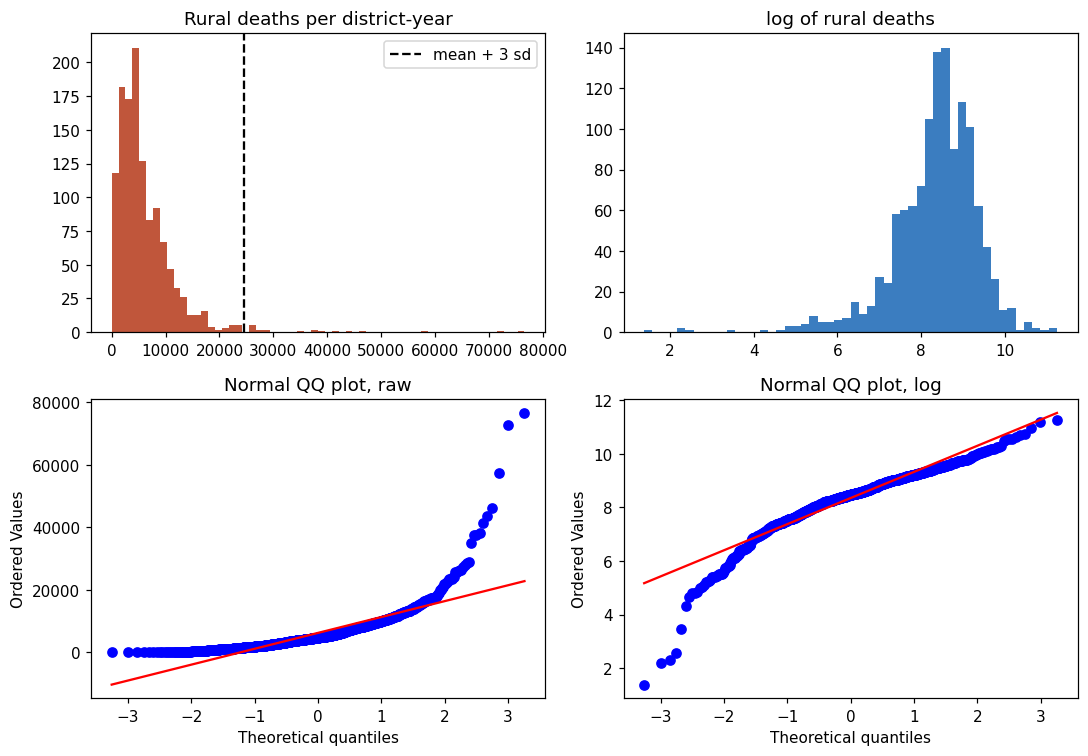

In [11]:
# how skewed are the counts? (district-year level)
def describe_skew(s, name):
    s = s.dropna()
    return {"variable": name, "n": len(s), "mean": s.mean(), "median": s.median(), "skew": stats.skew(s),
            "excess kurtosis": stats.kurtosis(s), "normality test p": stats.normaltest(s)[1],
            "skew after log": stats.skew(np.log(s[s > 0]))}

dogs = pd.read_csv(find("district_dogs_census_2012.csv"))
skew_table = pd.DataFrame([describe_skew(data.drural, "rural deaths"), describe_skew(data.total_deaths, "total deaths"),
                           describe_skew(data.rural_rate, "rural deaths per 1000"),
                           describe_skew(dogs.straydogs[dogs.straydogs > 0], "stray dogs 2012")])
print(skew_table.round(3).to_string(index=False))

fig, ax = plt.subplots(2, 2, figsize=(10, 7))
r = data.dropna(subset=["drural"])
ax[0, 0].hist(r.drural, bins=60, color="#c0563b")
ax[0, 0].axvline(r.drural.mean() + 3 * r.drural.std(), color="k", ls="--", label="mean + 3 sd")
ax[0, 0].set_title("Rural deaths per district-year"); ax[0, 0].legend()
ax[0, 1].hist(r.ln_drural, bins=50, color="#3b7dc0"); ax[0, 1].set_title("log of rural deaths")
stats.probplot(r.drural, plot=ax[1, 0]); ax[1, 0].set_title("Normal QQ plot, raw")
stats.probplot(r.ln_drural, plot=ax[1, 1]); ax[1, 1].set_title("Normal QQ plot, log")
plt.tight_layout()
plt.show()

In [12]:
# what does the 3-sigma rule actually delete?
r = r.copy()
r["z_raw"] = (r.drural - r.drural.mean()) / r.drural.std()
r["z_log"] = (r.ln_drural - r.ln_drural.mean()) / r.ln_drural.std()
r["z_rate"] = (r.rural_rate - r.rural_rate.mean()) / r.rural_rate.std()
cut = r[r.z_raw.abs() > 3]

print(f"3-sigma rule on raw counts removes {len(cut)} of {len(r)} district-years ({len(cut)/len(r):.1%}) from {cut.district_id.nunique()} districts")
print(f"on the log scale the same rule flags {(r.z_log.abs() > 3).sum()} points: {(r.z_log > 3).sum()} high, {(r.z_log < -3).sum()} low")
print()
who = cut.groupby("district_id").agg(years_removed=("year", "size"), mean_deaths=("drural", "mean"),
                                     population_1991=("poprural", "first"), mean_rate_per_1000=("rural_rate", "mean"))
print(who.sort_values("years_removed", ascending=False).round(1))
print()
print("average rural death rate of removed rows:", cut.rural_rate.mean().round(2), "| of kept rows:", r[r.z_raw.abs() <= 3].rural_rate.mean().round(2))
print("largest |z| of the removed rows when measured as a RATE:", cut.z_rate.abs().max().round(2))
print("average cattle (000) of removed districts:", cut.cattle.mean().round(0), "| of the rest:", r[r.z_raw.abs() <= 3].cattle.mean().round(0))

3-sigma rule on raw counts removes 19 of 1239 district-years (1.5%) from 7 districts
on the log scale the same rule flags 17 points: 0 high, 17 low

                           years_removed  mean_deaths  population_1991  mean_rate_per_1000
district_id                                                                               
orissa | cuttack                       5      27761.4        4844040.0                 5.7
uttar pradesh | allahabad              5      57558.4        3898948.0                14.8
uttar pradesh | bahraich               4      40876.5        2546844.0                16.0
uttar pradesh | moradabad              2      30659.5        2981566.0                10.3
orissa | koraput                       1      25988.0        2674970.0                 9.7
uttar pradesh | basti                  1      25610.0        2562696.0                10.0
uttar pradesh | budaun                 1      25660.0        1839169.0                14.0

average rural death rate of rem

In [13]:
# does trimming change the interaction result? (raw death counts, as in the proposal's plain linear regression)
r["ln_pop"] = np.log(r.poprural)
xs = ["vulture", "cattle_z", "vulture_x_cattle", "ln_pop"]
keep = r.z_raw.abs() <= 3
lo, hi = r.drural.quantile([0.01, 0.99])

rows = []
for name, d, y in [("raw counts, all data", r, "drural"),
                   ("raw counts, 3-sigma trimmed", r[keep], "drural"),
                   ("raw counts, winsorised at 1% / 99%", r.assign(drural=r.drural.clip(lo, hi)), "drural"),
                   ("log counts, all data", r, "ln_drural")]:
    res = ols(d, y, xs, fixed=["year"])
    rows.append({"model": name, "N": res.attrs["n"], "vulture x cattle": res.loc["vulture_x_cattle", "coef"],
                 "se": res.loc["vulture_x_cattle", "se"], "p-value": res.loc["vulture_x_cattle", "p"]})
print(pd.DataFrame(rows).round(3).to_string(index=False))

                             model    N  vulture x cattle       se  p-value
              raw counts, all data 1239          3021.725 1387.609    0.031
       raw counts, 3-sigma trimmed 1220          2042.949 1307.507    0.120
raw counts, winsorised at 1% / 99% 1239          2668.871 1315.498    0.044
              log counts, all data 1239             0.494    0.223    0.028



**What we see**

- Counts are strongly right-skewed (rural deaths: skew 4.3, excess kurtosis 34) and far less so after taking logs.
- The 3-sigma rule on raw counts deletes 19 district-years from 7 districts (Cuttack, Allahabad, Bahraich, Moradabad, Koraput, Basti, Budaun). Allahabad and Cuttack are removed in all five of their years, Bahraich in four. These are not one-off spikes or data errors.
- The removed rows have a rural death rate of 11.6 per 1000 against 3.7 for the rest, and about twice the cattle (1147 vs 547 thousand). The rule throws away the high-cattle, high-mortality districts that the hypothesis is about.
- On the log scale the same rule flags 17 points, all unusually *low* and none high. The odd values are at the bottom, which looks more like under-registration than outbreaks.
- Trimming changes the answer: the vulture × cattle coefficient falls from 3022 (p = 0.031) to 2043 (p = 0.12). Winsorising gives 2669 (p = 0.044), and the log model gives 0.494 (p = 0.028).

**Reading:** the extreme points are real and persistent, so they should be kept and handled with a log scale, not deleted. Persistent size is not the same as an outbreak; spotting an outbreak would mean looking at year-to-year jumps inside one district.


## 5. Q8 – Aggregation bias: state averages vs district data
Same model, same years (1988–95). First on the 218 districts, then after collapsing everything to one number per state and year.

In [14]:
# state-year numbers built from the districts
agg = data.groupby(["state", "year"]).agg(drural=("drural", "sum"), poprural=("poprural", "sum"),
                                         vulture=("vulture", "mean"), cattle=("cattle_z", "mean")).reset_index()
agg["ln_rural_rate"] = np.log(agg.drural / agg.poprural * 1000)
agg["vulture_x_cattle"] = agg.vulture * agg.cattle
agg = agg.rename(columns={"cattle": "cattle_z"})

state_fit = ols(agg, "ln_rural_rate", x, fixed=["year"], cluster="state")
report(state_fit, "State-level version of Model 1")
print("vulture x cattle coefficient")
print(f"   districts : {m1.loc['vulture_x_cattle','coef']:.3f}  (p = {m1.loc['vulture_x_cattle','p']:.3f}, N = {m1.attrs['n']})")
print(f"   states    : {state_fit.loc['vulture_x_cattle','coef']:.3f}  (p = {state_fit.loc['vulture_x_cattle','p']:.3f}, N = {state_fit.attrs['n']})")

State-level version of Model 1 (N = 113, clusters = 15)
                   coef     se      t      p
vulture           0.465  0.317  1.466  0.165
cattle_z         -0.465  0.272 -1.707  0.110
vulture_x_cattle  0.566  0.278  2.035  0.061

vulture x cattle coefficient
   districts : 0.636  (p = 0.003, N = 1239)
   states    : 0.566  (p = 0.061, N = 113)


correlation of cattle with log rural death rate
   across districts       : 0.112  (n = 164)
   across state averages  : -0.178  (n = 15)
   inside states          : 0.131


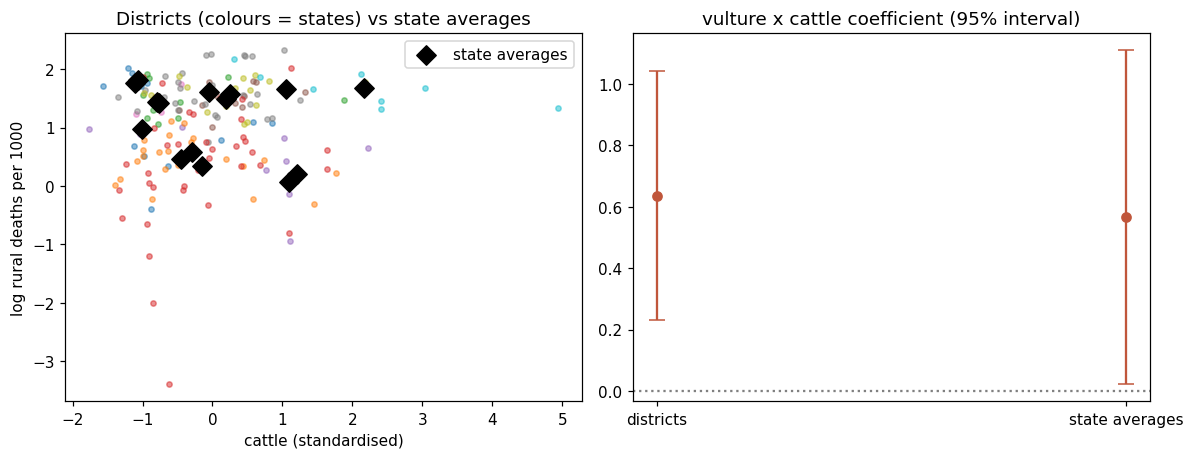

In [15]:
# correlation between cattle and the death rate, at three levels
dist_mean = data.groupby(["state", "district"])[["cattle_z", "ln_rural_rate"]].mean().reset_index()
state_mean = data.groupby("state")[["cattle_z", "ln_rural_rate"]].mean().reset_index()
within = dist_mean.assign(c=lambda d: d.cattle_z - d.groupby("state").cattle_z.transform("mean"),
                          y=lambda d: d.ln_rural_rate - d.groupby("state").ln_rural_rate.transform("mean"))
print("correlation of cattle with log rural death rate")
print(f"   across districts       : {dist_mean.cattle_z.corr(dist_mean.ln_rural_rate):.3f}  (n = {len(dist_mean)})")
print(f"   across state averages  : {state_mean.cattle_z.corr(state_mean.ln_rural_rate):.3f}  (n = {len(state_mean)})")
print(f"   inside states          : {within.c.corr(within.y):.3f}")

fig, ax = plt.subplots(1, 2, figsize=(11, 4.3))
for s, g in dist_mean.groupby("state"):
    ax[0].scatter(g.cattle_z, g.ln_rural_rate, s=12, alpha=0.5)
ax[0].scatter(state_mean.cattle_z, state_mean.ln_rural_rate, s=80, c="k", marker="D", label="state averages")
ax[0].set_xlabel("cattle (standardised)"); ax[0].set_ylabel("log rural deaths per 1000")
ax[0].set_title("Districts (colours = states) vs state averages"); ax[0].legend()
ax[1].errorbar([0, 1], [m1.loc["vulture_x_cattle", "coef"], state_fit.loc["vulture_x_cattle", "coef"]],
               yerr=[1.96 * m1.loc["vulture_x_cattle", "se"], 1.96 * state_fit.loc["vulture_x_cattle", "se"]],
               fmt="o", capsize=5, color="#c0563b")
ax[1].axhline(0, color="grey", ls=":"); ax[1].set_xticks([0, 1]); ax[1].set_xticklabels(["districts", "state averages"])
ax[1].set_title("vulture x cattle coefficient (95% interval)")
plt.tight_layout()
plt.show()

In [16]:
# the proposal's other argument: cities (no cattle) dilute the rural signal in a state total.
# State panel, same before/after model, rural death rate vs the all-areas death rate.
m5 = ols(sp, "ln_total", ["v_post", "c_post", "vc_post"], fixed=["state", "year"], cluster="state")
print("vulture x post, state panel 1988-2005")
print(f"   rural death rate : {m4.loc['v_post','coef']:.3f}  (p = {m4.loc['v_post','p']:.3f})")
print(f"   total death rate : {m5.loc['v_post','coef']:.3f}  (p = {m5.loc['v_post','p']:.3f})")
urban_share = data.durban.sum() / (data.durban.sum() + data.drural.sum())
print(f"urban areas account for {urban_share:.0%} of registered deaths in the district sample")

vulture x post, state panel 1988-2005
   rural death rate : 0.001  (p = 0.986)
   total death rate : -0.007  (p = 0.830)
urban areas account for 32% of registered deaths in the district sample



**What we see**

- The vulture × cattle coefficient is 0.64 (p = 0.003) with 164 districts and 0.57 (p = 0.061) with 15 states. The estimate hardly moves; the significance drops because the number of units falls from 164 to 15. So in this data averaging costs power more than it hides the effect.
- The sign of the cattle–death-rate relationship does flip with the level of aggregation: +0.11 across districts, +0.13 inside states, but −0.18 across state averages. That is the aggregation fallacy in a small form, though 15 states is thin evidence.
- Urban areas are 32% of registered deaths, but the state before/after model finds nothing for either the rural rate (0.001) or the total rate (−0.007), so there is no effect for the cities to dilute.

## Limits to mention in the report

- District data end in 1995, before most of the vulture collapse. The state panel (to 2005) is the only post-collapse look.
- There is no rabies series in the files, so the outcome is registered deaths.
- The no-vulture comparison group is only 15 districts, and the sample falls from 181 to 164 districts because cattle or population is missing for some.
- Registered deaths depend on how complete registration is, which differs by state.


In [17]:
# save the cleaned analysis table for the report / charts
out_dir = "../data/clean" if os.path.isdir("../data/clean") else "."
df.to_csv(os.path.join(out_dir, "district_panel_with_rates.csv"), index=False)
print("saved", os.path.join(out_dir, "district_panel_with_rates.csv"), df.shape)

saved ./district_panel_with_rates.csv (1400, 20)
